# Telco Churn: EDA and Model Training

## Step 1: Load data

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

ROOT = Path("..") if Path("../data").exists() else Path(".")
PLOTS = ROOT / "notebooks" / "plots"
MODELS = ROOT / "models"
PLOTS.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ROOT / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Step 2: Exploratory data analysis

       count  percent
Churn                
No      5174    73.46
Yes     1869    26.54


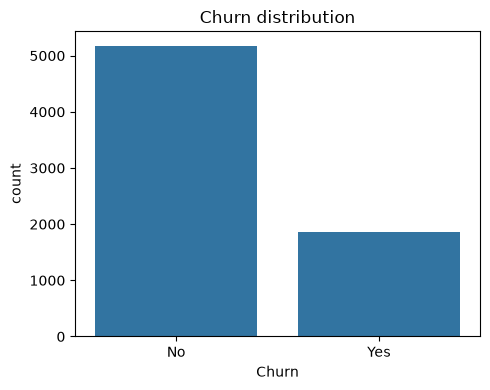

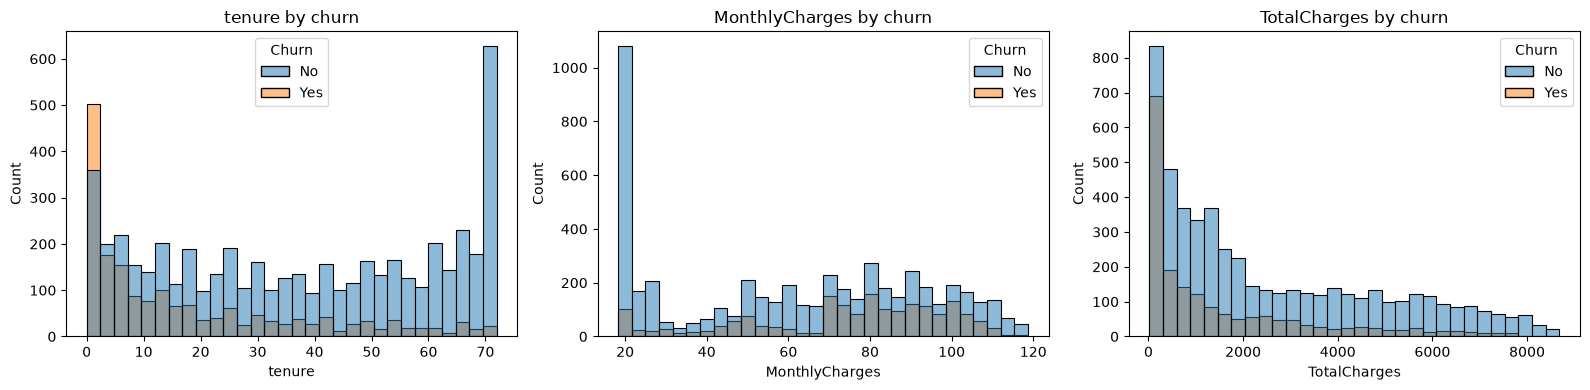

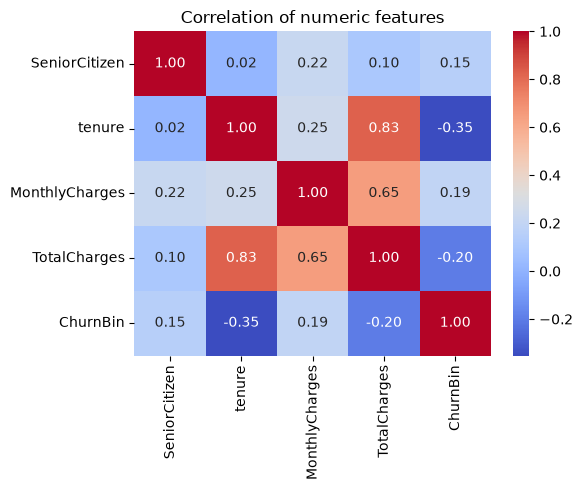

In [2]:
counts = df["Churn"].value_counts()
pcts = df["Churn"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": pcts.round(2)}))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="Churn", ax=ax)
ax.set_title("Churn distribution")
fig.tight_layout()
fig.savefig(PLOTS / "churn_distribution.png", dpi=120)
plt.show()

eda = df.copy()
eda["TotalCharges"] = pd.to_numeric(eda["TotalCharges"], errors="coerce")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=eda, x=col, hue="Churn", bins=30, ax=ax)
    ax.set_title(f"{col} by churn")
fig.tight_layout()
fig.savefig(PLOTS / "numeric_histograms.png", dpi=120)
plt.show()

eda["ChurnBin"] = (eda["Churn"] == "Yes").astype(int)
corr = eda[["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", "ChurnBin"]].corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
ax.set_title("Correlation of numeric features")
fig.tight_layout()
fig.savefig(PLOTS / "correlation_heatmap.png", dpi=120)
plt.show()

## Step 3: Clean data

In [3]:
data = df.copy()
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"].replace(r"^\s*$", np.nan, regex=True), errors="coerce")
print("Rows with missing TotalCharges:", data["TotalCharges"].isna().sum())
data = data.dropna(subset=["TotalCharges"])
data = data.drop(columns=["customerID"])
data["Churn"] = (data["Churn"] == "Yes").astype(int)
cat_cols = data.select_dtypes(exclude="number").columns.tolist()
data = pd.get_dummies(data, columns=cat_cols, drop_first=True, dtype=int)
print("Cleaned shape:", data.shape)
X = data.drop(columns="Churn")
y = data["Churn"]

Rows with missing TotalCharges: 11
Cleaned shape: (7032, 31)


## Step 4: Stratified 70/15/15 split

In [4]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)
for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(name, len(part), f"churn rate={part.mean():.4f}")

train 4922 churn rate=0.2657
val 1055 churn rate=0.2664
test 1055 churn rate=0.2654


## Step 5: Logistic regression baseline with 5-fold stratified CV

In [5]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]


def make_preprocessor():
    return ColumnTransformer([("num", StandardScaler(), num_cols)], remainder="passthrough")


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_pipe = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000)),
])
lr_scores = cross_val_score(lr_pipe, X_train, y_train, cv=cv, scoring="roc_auc")
print("Logistic regression CV ROC-AUC per fold:", np.round(lr_scores, 4))
print("Logistic regression mean CV ROC-AUC:", round(lr_scores.mean(), 4))

Logistic regression CV ROC-AUC per fold: [0.8387 0.8292 0.8529 0.8598 0.8572]
Logistic regression mean CV ROC-AUC: 0.8476


## Step 6: XGBoost with 5-fold stratified CV

In [6]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
spw = neg / pos
print("scale_pos_weight:", round(spw, 4))

xgb_pipe = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", XGBClassifier(scale_pos_weight=spw, eval_metric="logloss", random_state=42, n_jobs=-1)),
])
xgb_scores = cross_val_score(xgb_pipe, X_train, y_train, cv=cv, scoring="roc_auc")
print("XGBoost CV ROC-AUC per fold:", np.round(xgb_scores, 4))
print("XGBoost mean CV ROC-AUC:", round(xgb_scores.mean(), 4))

scale_pos_weight: 2.763


XGBoost CV ROC-AUC per fold: [0.8155 0.7941 0.8267 0.8293 0.8366]
XGBoost mean CV ROC-AUC: 0.8204


## Step 7: Test set evaluation and threshold tuning

In [7]:
lr_pipe.fit(X_train, y_train)
xgb_pipe.fit(X_train, y_train)


def metrics_at(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "roc_auc": float(roc_auc_score(y_true, proba)),
        "pr_auc": float(average_precision_score(y_true, proba)),
        "precision": float(precision_score(y_true, pred, zero_division=0)),
        "recall": float(recall_score(y_true, pred)),
        "f1": float(f1_score(y_true, pred)),
    }


lr_test_proba = lr_pipe.predict_proba(X_test)[:, 1]
xgb_test_proba = xgb_pipe.predict_proba(X_test)[:, 1]
lr_metrics = metrics_at(y_test, lr_test_proba)
xgb_metrics = metrics_at(y_test, xgb_test_proba)
print(pd.DataFrame({"logistic_regression": lr_metrics, "xgboost (0.5)": xgb_metrics}).round(4))

# Tune the XGBoost threshold on the validation set by maximizing F1
xgb_val_proba = xgb_pipe.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, xgb_val_proba)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
best_threshold = float(thr[np.argmax(f1s)])
print("Tuned threshold (max validation F1):", round(best_threshold, 4))

xgb_tuned_metrics = metrics_at(y_test, xgb_test_proba, best_threshold)
print("XGBoost test metrics at tuned threshold:")
print(pd.Series(xgb_tuned_metrics).round(4))

tn, fp, fn, tp = confusion_matrix(y_test, (xgb_test_proba >= best_threshold).astype(int)).ravel()
xgb_tuned_confusion = {
    "true_negative": int(tn),
    "false_positive": int(fp),
    "false_negative": int(fn),
    "true_positive": int(tp),
}
print("XGBoost test confusion matrix at tuned threshold:", xgb_tuned_confusion)

           logistic_regression  xgboost (0.5)
roc_auc                 0.8222         0.7921
pr_auc                  0.5800         0.5445
precision               0.4910         0.5289
recall                  0.7786         0.6536
f1                      0.6022         0.5847
Tuned threshold (max validation F1): 0.4672
XGBoost test metrics at tuned threshold:
roc_auc      0.7921
pr_auc       0.5445
precision    0.5223
recall       0.6679
f1           0.5862
dtype: float64
XGBoost test confusion matrix at tuned threshold: {'true_negative': 604, 'false_positive': 171, 'false_negative': 93, 'true_positive': 187}


## Step 8: Calibration of the XGBoost model

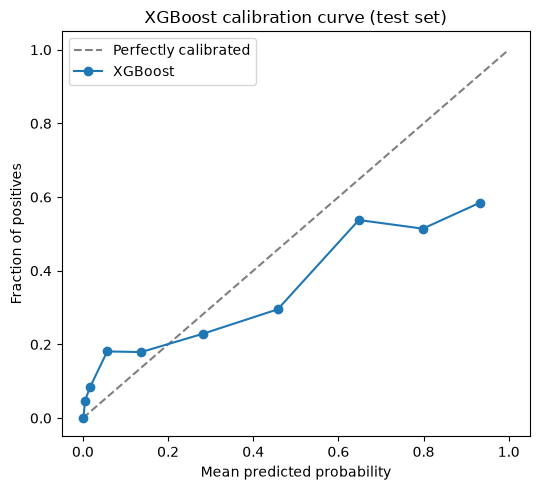

In [8]:
frac_pos, mean_pred = calibration_curve(y_test, xgb_test_proba, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfectly calibrated")
ax.plot(mean_pred, frac_pos, "o-", label="XGBoost")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Fraction of positives")
ax.set_title("XGBoost calibration curve (test set)")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "xgboost_calibration.png", dpi=120)
plt.show()

## Step 9: Save pipeline and metrics

In [9]:
joblib.dump(xgb_pipe, MODELS / "pipeline.joblib")

out = {
    "threshold": best_threshold,
    "feature_columns": X.columns.tolist(),
    "xgboost_test_default_threshold": xgb_metrics,
    "xgboost_test_tuned_threshold": xgb_tuned_metrics,
    "xgboost_test_tuned_confusion_matrix": xgb_tuned_confusion,
    "logistic_regression_test": lr_metrics,
    "cv_mean_roc_auc": {"logistic_regression": float(lr_scores.mean()), "xgboost": float(xgb_scores.mean())},
}
with open(MODELS / "metrics.json", "w") as f:
    json.dump(out, f, indent=2)

reloaded = joblib.load(MODELS / "pipeline.joblib")
assert np.allclose(reloaded.predict_proba(X_test)[:, 1], xgb_test_proba)
print("Saved pipeline.joblib and metrics.json")

Saved pipeline.joblib and metrics.json
